# Spotify · первичный анализ и очистка данных
Цель этапа — подготовить проверенный каталог для поиска музыки по любимому треку пользователя. Результатом служат две связанные таблицы, описательная статистика и графики. Порядок чтения блокнота соответствует движению данных от исходного CSV до сохранённых файлов.

### 1. Подключение и загрузка
Первая ячейка подключает Google Диск к сеансу Colab. Вторая читает исходный CSV в таблицу pandas и показывает первые записи. Первичный просмотр помогает проверить путь, названия столбцов и содержание полей перед обработкой.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

import pandas as pd
import sklearn

csv_path = Path("/content/drive/MyDrive/Colab Notebooks/Spotify_ARD/data/raw/dataset.csv")
df = pd.read_csv(csv_path)

print("Версия scikit-learn:", sklearn.__version__)
print(f"Строк: {len(df):,}")
print(f"Столбцов: {df.shape[1]}")
print(f"Уникальных track_id: {df['track_id'].nunique():,}")

display(df[["track_name", "artists", "track_genre", "energy", "tempo"]].head())

Версия scikit-learn: 1.6.1
Строк: 114,000
Столбцов: 21
Уникальных track_id: 89,741


,track_name,artists,track_genre,energy,tempo
0,Comedy,Gen Hoshino,acoustic,0.4610,87.917
1,Ghost - Acoustic,Ben Woodward,acoustic,0.1660,77.489
2,To Begin Again,Ingrid Michaelson;ZAYN,acoustic,0.3590,76.332
3,Can't Help Falling In Love,Kina Grannis,acoustic,0.0596,181.740
4,Hold On,Chord Overstreet,acoustic,0.4430,119.949


### 2. Что означает одна строка CSV?
Для рекомендаций нам нужен один кандидат на каждый Spotify ID. Сначала считаем отдельно строки, уникальные ID и жанры. В CSV 114 000 строк, 89 741 уникальный ID и 114 жанров. Ни в одной строке ID не пропущен.

В выводе важно различать две величины. 16 641 — число треков, у которых есть повторы. 24 259 — общее число строк сверх первого вхождения каждого ID. Если трек записан трижды, он добавляет единицу к первой величине и две ко второй.

Посмотрите на *Mr. Brightside* в конце таблицы. Название, энергия и темп совпадают, но у трека три жанра. Если просто оставить первую строку, две метки исчезнут. Всего несколько жанров имеют 16 299 треков.

In [ ]:
# 1. В каких столбцах есть пропуски?
missing = df.isna().sum()
print("Пропуски в track_id:", missing["track_id"])
print("Столбцы с пропусками:")
display(missing[missing > 0].rename("Количество пропусков").to_frame())

# 2. Сколько треков встречаются повторно и у скольких несколько жанров?
tracks = df.groupby("track_id").agg(
    rows=("track_id", "size"),
    genres=("track_genre", "nunique"),
)

print("Уникальных жанров в каталоге:", df["track_genre"].nunique())
print("Треков, встречающихся больше одного раза:", (tracks["rows"] > 1).sum())
print("Повторных строк сверх первой для каждого ID:", (tracks["rows"] - 1).sum())
print("Треков с несколькими жанрами:", (tracks["genres"] > 1).sum())

# 3. Посмотрим на три конкретных трека с несколькими жанрами
example_ids = tracks.loc[tracks["genres"] > 1].head(3).index
columns = ["track_id", "track_name", "artists", "track_genre", "energy", "tempo"]

display(
    df.loc[df["track_id"].isin(example_ids), columns]
    .sort_values(["track_id", "track_genre"])
)

Пропуски в track_id: 0
Столбцы с пропусками:


,Количество пропусков
artists,1
album_name,1
track_name,1


Уникальных жанров в каталоге: 114
Треков, встречающихся больше одного раза: 16641
Повторных строк сверх первой для каждого ID: 24259
Треков с несколькими жанрами: 16299


,track_id,track_name,artists,track_genre,energy,tempo
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill,0.471,143.064
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul,0.471,143.064
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock,0.921,183.571
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska,0.921,183.571
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alt-rock,0.911,148.033
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative,0.911,148.033
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock,0.911,148.033


### 3. Можно ли объединить повторные записи?
Сначала смотрим на три пропуска в полях исполнителя, альбома и названия. Проверка по ID показывает, что все три относятся к одной записи. Другой строки с этим ID в CSV нет, поэтому восстановить подпись композиции из нашего источника невозможно.

Затем для каждого повторяющегося ID считаем количество различных значений в каждом поле. Ноль в итоговой таблице означает, что ни у одного такого ID значения поля не расходятся. Аудиопризнаки согласованы во всех проверенных группах. У 720 ID различаются оценки популярности. Поэтому характеристики звучания можно взять из одной записи, а для популярности требуется отдельное правило.

In [ ]:
# 1. Показываем строки с пропусками и все записи с теми же track_id
metadata = ["artists", "album_name", "track_name"]
missing_rows = df[metadata].isna().any(axis=1)
affected_ids = df.loc[missing_rows, "track_id"]

print("Строк с пропусками в метаданных:", missing_rows.sum())
display(
    df.loc[df["track_id"].isin(affected_ids),
           ["track_id", *metadata, "track_genre"]]
    .sort_values("track_id")
)

# 2. Для повторяющихся ID проверяем все поля, кроме жанра и номера строки
repeated = df.loc[df["track_id"].duplicated(keep=False)]
fields = df.columns.drop(["track_id", "track_genre", "Unnamed: 0"], errors="ignore")

distinct_values = repeated.groupby("track_id")[fields].nunique(dropna=False)
conflicts = distinct_values.gt(1)

print("ID с различиями хотя бы в одном проверяемом поле:",
      conflicts.any(axis=1).sum())

field_counts = conflicts.sum().sort_values(ascending=False)
display(field_counts.rename("Число ID с различиями").to_frame())

Строк с пропусками в метаданных: 1


,track_id,artists,album_name,track_name,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,k-pop


ID с различиями хотя бы в одном проверяемом поле: 720


,Число ID с различиями
popularity,720
artists,0
album_name,0
track_name,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0
loudness,0


### 4. Проверка структуры и диапазонов
Таблица типов показывает, какие поля содержат текст, числа и логические значения. Контрольная сумма SHA-256 позволяет при следующем запуске убедиться, что исходный CSV побайтово совпадает с использованной версией.

Для признаков со шкалой от 0 до 1, например энергии, проверяем обе границы. Для громкости в децибелах отрицательные значения допустимы, поэтому здесь проверяем конечность числа. Отдельно считаем полные совпадения по всем содержательным полям. Если убрать служебный номер строки, обнаруживается 450 таких повторов. Это более строгая проверка, чем совпадение одного ID.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import hashlib

print("SHA-256 исходного CSV:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
schema = pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum(),
                       "уникальные значения": df.nunique()})
display(schema)
unit = ["danceability", "energy", "speechiness", "acousticness",
        "instrumentalness", "liveness", "valence"]
audio = unit + ["tempo", "loudness"]
checks = {c: df[c].between(0, 1) for c in unit}
checks.update(popularity=df.popularity.between(0, 100), duration_ms=df.duration_ms.gt(0),
              tempo=df.tempo.ge(0), key=df.key.isin(range(-1, 12)),
              mode=df["mode"].isin([0, 1]), explicit=df.explicit.isin([True, False]),
              time_signature=df.time_signature.isin([0, 1, 2, 3, 4, 5, 6, 7]),
              loudness=np.isfinite(df.loudness))
valid = pd.DataFrame(checks) & np.isfinite(df[list(checks)])
display((~valid).sum().to_frame("Нарушения по строкам"))
print("Точных повторов строк без номера CSV:",
      df.drop(columns="Unnamed: 0", errors="ignore").duplicated().sum())

,тип,пропуски,уникальные значения
Unnamed: 0,int64,0,114000
track_id,object,0,89741
artists,object,1,31437
album_name,object,1,46589
track_name,object,1,73608
popularity,int64,0,101
duration_ms,int64,0,50697
explicit,bool,0,2
danceability,float64,0,1174
energy,float64,0,2083


,Нарушения по строкам
danceability,0
energy,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0
popularity,0
duration_ms,1
tempo,0


SHA-256 исходного CSV: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
Точных повторов строк без номера CSV: 450


### 5. Как из строк получается каталог
Сохраняем записи с заполненными ID, названием и исполнителем, прошедшие проверки значений. Одна запись без подписи исключается из пользовательской выдачи. Перед объединением код дополнительно проверяет согласованность постоянных полей командой `assert`: если в новой версии данных у одного ID разойдётся, например, темп, выполнение остановится именно здесь.

Формируем две таблицы. В каталоге трек занимает одну строку, а в таблице жанров каждая уникальная пара «ID — жанр» занимает свою строку. Так один трек можно найти по любому из его жанров и выдать один раз.

Для популярности сохраняем минимум, максимум и медиану различных наблюдавшихся значений. Повтор одной оценки в нескольких жанрах не увеличивает её вес. Медиана служит сводной характеристикой и не указывает, какая оценка была последней.

In [ ]:
usable = valid.all(axis=1) & df[["track_name", "artists", "track_id"]].notna().all(axis=1)
base = df.loc[usable].drop(columns="Unnamed: 0", errors="ignore")
fixed = base.columns.difference(["track_id", "track_genre", "popularity"])
assert base.groupby("track_id")[fixed].nunique(dropna=False).le(1).all().all()
catalog = base.drop(columns=["track_genre", "popularity"]).drop_duplicates("track_id")
genres = base[["track_id", "track_genre"]].dropna().drop_duplicates()
scores = base[["track_id", "popularity"]].drop_duplicates().groupby("track_id").popularity
catalog = catalog.join(scores.agg(popularity="median", popularity_min="min",
                                  popularity_max="max"), on="track_id")
assert catalog.track_id.is_unique and set(catalog.track_id) == set(genres.track_id)
assert len(genres) == base.groupby("track_id").track_genre.nunique().sum()
print("Исключено исходных строк:", (~usable).sum())
print("Треков в каталоге:", len(catalog), "| связей трек–жанр:", len(genres))
print("Жанров:", genres.track_genre.nunique(), "| треков с несколькими жанрами:",
      genres.groupby("track_id").size().gt(1).sum())
print("ID с разными оценками популярности:", catalog.popularity_min.ne(catalog.popularity_max).sum())

Исключено исходных строк: 1
Треков в каталоге: 89740 | связей трек–жанр: 113549
Жанров: 114 | треков с несколькими жанрами: 16299
ID с разными оценками популярности: 720


### 6. Как читать распределения
Статистику считаем после объединения ID, чтобы трек с тремя жанрами влиял на среднее так же, как трек с одним жанром. В таблице 50% — медиана, а интервал между 1% и 99% описывает центральную часть наблюдений. Сравнение 99-го процентиля с максимумом помогает заметить редкие большие значения.

На гистограмме по горизонтали отложено значение признака, по вертикали — число треков в интервале. Например, длинный правый хвост длительности означает, что есть отдельные композиции заметно длиннее большинства. Само по себе это не доказывает ошибку.

Отдельно учитываем 157 треков с нулевым темпом и 162 с нулевым размером такта. Эти записи сохраняем. Перед поиском по темпу нужно выбрать, как обращаться с нулём, чтобы он не создавал искусственное сходство.

,count,mean,std,min,1%,25%,50%,75%,99%,max
danceability,89740.0,0.562,0.177,0.000,0.123,0.450,0.576,0.692,0.904,0.985
energy,89740.0,0.634,0.257,0.000,0.027,0.457,0.676,0.853,0.993,1.000
speechiness,89740.0,0.087,0.113,0.000,0.026,0.036,0.049,0.086,0.619,0.965
acousticness,89740.0,0.328,0.338,0.000,0.000,0.017,0.188,0.625,0.992,0.996
instrumentalness,89740.0,0.173,0.324,0.000,0.000,0.000,0.000,0.098,0.958,1.000
liveness,89740.0,0.217,0.195,0.000,0.041,0.098,0.132,0.279,0.950,1.000
valence,89740.0,0.469,0.263,0.000,0.033,0.249,0.457,0.682,0.965,0.995
tempo,89740.0,122.058,30.118,0.000,65.165,99.263,122.013,140.077,193.652,243.372
loudness,89740.0,-8.499,5.222,-49.531,-28.542,-10.322,-7.185,-5.108,-1.628,4.532
duration_ms,89740.0,229144.366,112945.780,8586.000,61871.850,173040.000,213295.500,264293.000,546010.980,5237295.000


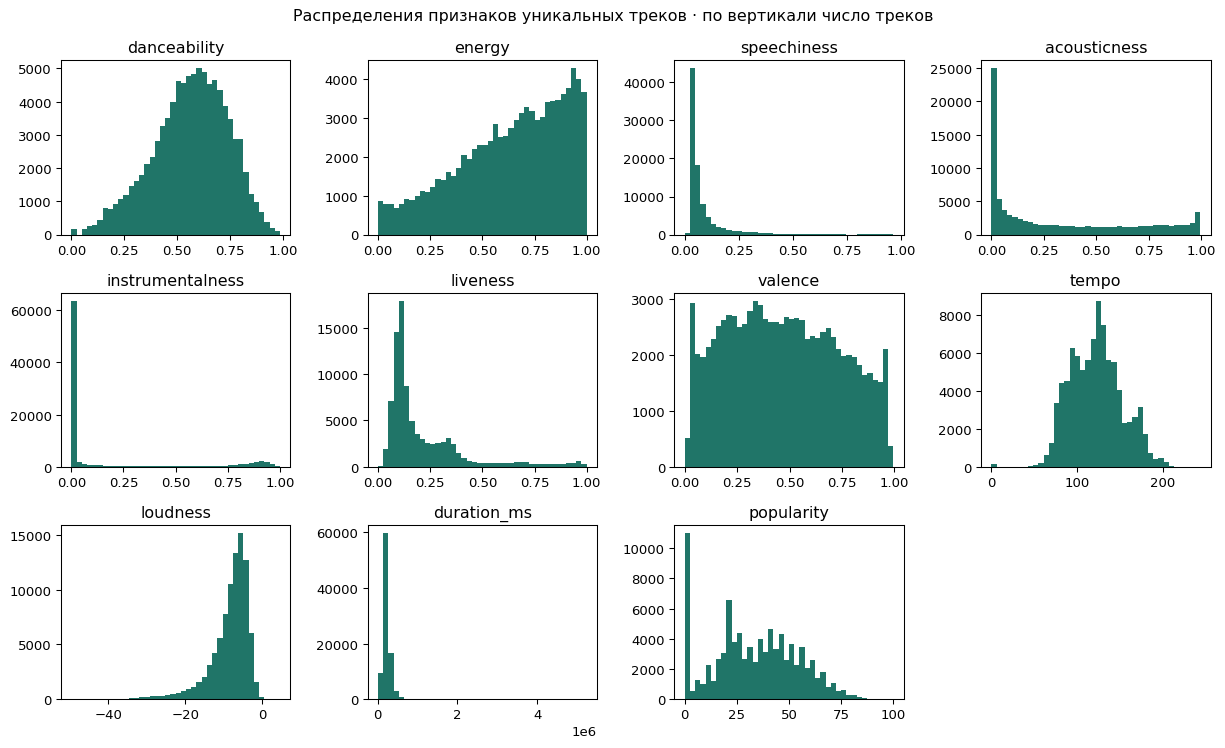

Темп равен нулю: 157 | нулевой размер такта: 162


In [ ]:
features = audio + ["duration_ms", "popularity"]
display(catalog[features].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))
print("Темп равен нулю:", catalog.tempo.eq(0).sum(),
      "| нулевой размер такта:", catalog.time_signature.eq(0).sum())
fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, col in zip(axes.flat, features):
    ax.hist(catalog[col], bins=40, color="#207568")
    ax.set_title(col)
axes.flat[-1].set_visible(False)
fig.suptitle("Распределения признаков уникальных треков · по вертикали число треков")
fig.tight_layout()
plt.show()

### 7. Какие признаки связаны и как представлены жанры
В матрице каждая клетка соответствует паре признаков. Знак коэффициента показывает направление связи, модуль — её выраженность. Диагональ равна единице, поскольку каждый признак сравнивается с самим собой.

На диаграмме энергии и громкости шестиугольники объединяют близкие наблюдения. Цвет показывает количество треков в ячейке по логарифмической шкале. Корреляция Пирсона равна 0,759, ранговая корреляция Спирмена — 0,753. В этом каталоге у более энергичных композиций громкость обычно выше. В дальнейшем проверим, насколько совместное использование этих признаков меняет рекомендации.

Диаграмма жанров считает треки по уникальным парам «ID — жанр». Один трек может войти сразу в несколько столбцов, поэтому сумма по всем жанрам превышает размер каталога.

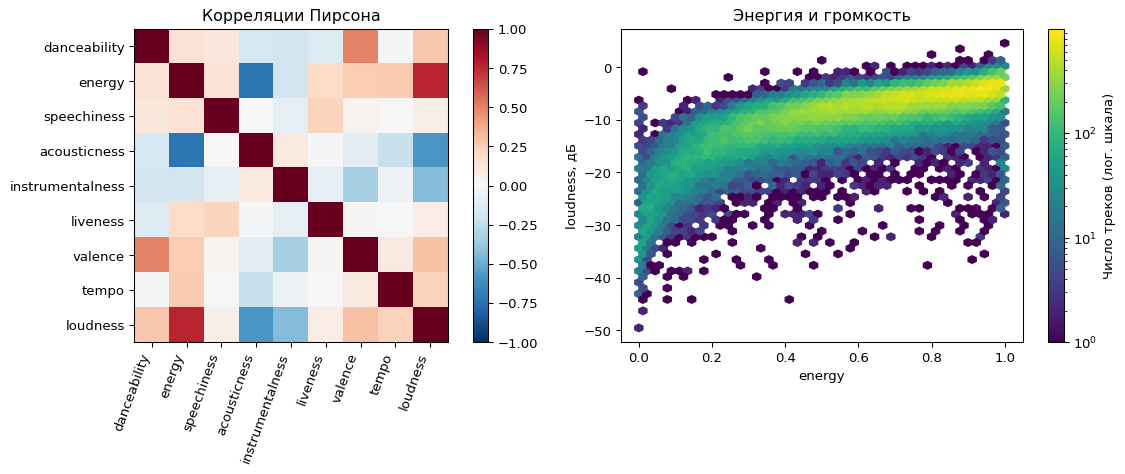

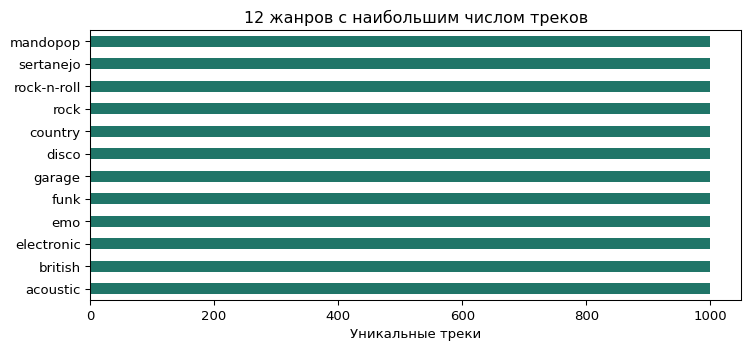

energy × loudness: Пирсон 0.759 | Спирмен 0.753
Число треков на жанр: от 904 до 1000


In [ ]:
counts = genres.track_genre.value_counts()
corr = catalog[audio].corr()
pair = catalog[["energy", "loudness"]]
print("energy × loudness: Пирсон", round(pair.corr().iloc[0, 1], 3),
      "| Спирмен", round(pair.rank().corr().iloc[0, 1], 3))
print("Число треков на жанр: от", counts.min(), "до", counts.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set_xticks(range(len(audio)), audio, rotation=70, ha="right")
axes[0].set_yticks(range(len(audio)), audio)
axes[0].set_title("Корреляции Пирсона")
fig.colorbar(im, ax=axes[0])
density = axes[1].hexbin(pair.energy, pair.loudness, gridsize=45, bins="log", mincnt=1)
axes[1].set(xlabel="energy", ylabel="loudness, дБ", title="Энергия и громкость")
fig.colorbar(density, ax=axes[1], label="Число треков (лог. шкала)")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 3.8))
counts.nlargest(12).sort_values().plot.barh(ax=ax, color="#207568")
ax.set(xlabel="Уникальные треки", ylabel="", title="12 жанров с наибольшим числом треков")
fig.tight_layout()
plt.show()

### 8. Что сохраняется и как проверяется результат
В `data/processed/tracks.csv` сохраняем по одной записи на трек, в `data/processed/track_genres.csv` — его связи с жанрами. Чтобы получить все жанры выбранной композиции, достаточно взять её ID из первой таблицы и найти все строки с этим ID во второй.

После записи читаем каждый CSV обратно и сравниваем с таблицей в памяти. Проверяем значения и порядок строк. Это позволяет обнаружить ошибку выгрузки до того, как данные попадут в следующий блокнот. Исходный файл хранится отдельно в `data/raw`.

In [ ]:
output_dir = csv_path.parent.parent / "processed"
output_dir.mkdir(exist_ok=True)
catalog.to_csv(output_dir / "tracks.csv", index=False)
genres.to_csv(output_dir / "track_genres.csv", index=False)
for filename, table in [("tracks.csv", catalog), ("track_genres.csv", genres)]:
    saved = pd.read_csv(output_dir / filename)
    pd.testing.assert_frame_equal(saved, table.reset_index(drop=True), check_dtype=False)
    print(filename, "— проверено строк:", len(saved))

tracks.csv — проверено строк: 89740
track_genres.csv — проверено строк: 113549


### Выводы
Из 114,000 исходных строк сформирован каталог из 89,740 треков. Исключена строка без названия и исполнителя. Все жанровые связи доступных для выдачи треков сохранены.

Энергия и громкость положительно связаны (Пирсон 0.759). При подборе похожих треков отдельно проверим, как одновременное включение обоих признаков влияет на выдачу. Темп и громкость измеряются в разных единицах и потребуют масштабирования. Популярность описывает каталог и не является оценкой конкретного слушателя. Модели на этом этапе не обучались.

## Парные графики для защиты · до и после очистки
В каждой ячейке вне диагонали показана связь двух характеристик, на диагонали — гистограмма одной характеристики. Выбраны пять признаков, чтобы подписи оставались читаемыми на слайде.

Две матрицы используют одинаковые пределы осей. Исходные строки могут повторять один трек в нескольких жанрах, после очистки каждый ID учитывается один раз. Поэтому главным изменением будет плотность наблюдений. Автоматического удаления всех крайних значений в нашей работе нет. Нулевой темп на этом этапе сохраняется. В исходном примере красные обводки отмечали аномалии размеров бриллиантов; в Spotify редкое значение само по себе не доказывает ошибку.

Изображения PNG 300 dpi и PDF сохраняются в папку figures. Для scatter используется случайная подвыборка до 3000 строк; гистограммы строятся по всей таблице.


In [20]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project = Path("/content/drive/MyDrive/Colab Notebooks/Spotify_ARD")
figures = project / "figures"
figures.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

def pair_matrix(frame, fields, title, subtitle, filename, color="#2879ae", limits=None):
    # Диагональ использует все строки, scatter — воспроизводимую подвыборку.
    sample = frame.sample(min(3000, len(frame)), random_state=42)
    count = len(fields)
    fig, axes = plt.subplots(count, count, figsize=(12, 11))
    for row, vertical in enumerate(fields):
        for col, horizontal in enumerate(fields):
            ax = axes[row, col]
            if row == col:
                ax.hist(frame[horizontal].dropna(), bins=32, color=color, alpha=0.85,
                        range=None if limits is None else limits[horizontal])
            else:
                ax.scatter(sample[horizontal], sample[vertical], s=3, alpha=0.18,
                           color=color, linewidths=0, rasterized=True)
                if limits:
                    ax.set_ylim(*limits[vertical])
            if limits:
                ax.set_xlim(*limits[horizontal])
            ax.spines[["top","right"]].set_visible(False)
            ax.tick_params(labelsize=7, length=2)
            ax.grid(alpha=0.12)
            if row == count-1:
                ax.set_xlabel(horizontal, fontsize=10)
            else:
                ax.tick_params(labelbottom=False)
            if col == 0:
                ax.set_ylabel(vertical if row != col else "Число записей", fontsize=10)
            else:
                ax.tick_params(labelleft=False)
    fig.suptitle(title, x=0.08, y=0.98, ha="left", fontsize=21, fontweight="bold")
    fig.text(0.08, 0.94, subtitle, ha="left", fontsize=11, color="#455365")
    fig.text(0.08, 0.025,
             f"Диагональ — распределения всех {len(frame):,} записей; "
             f"вне диагонали — {len(sample):,} точек. Зерно выборки 42.",
             fontsize=10, color="#455365")
    fig.subplots_adjust(left=0.08,right=0.98,top=0.90,bottom=0.09,hspace=0.17,wspace=0.17)
    fig.savefig(figures / (filename+".png"), dpi=300, facecolor="white")
    fig.savefig(figures / (filename+".pdf"), dpi=200, facecolor="white")
    plt.show()


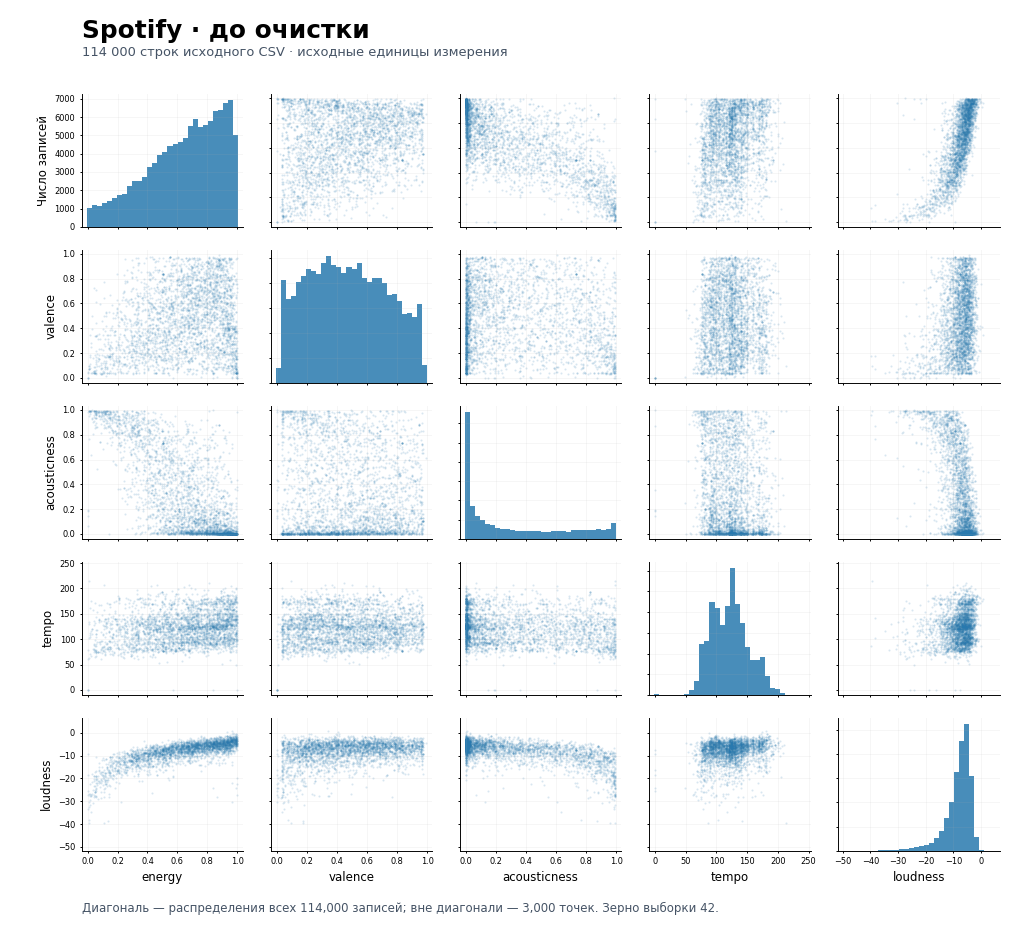

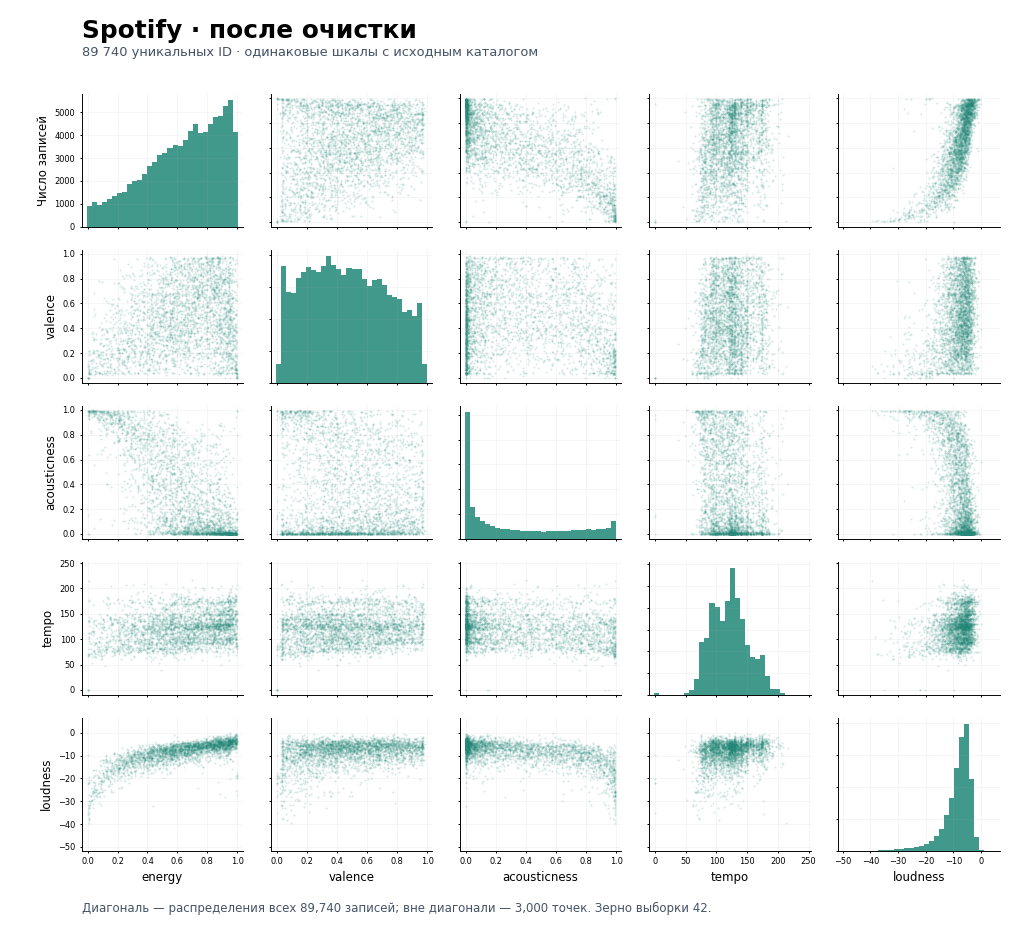

Диапазоны осей согласованы. Масштабирование и замена нулевого темпа здесь ещё не применялись.


In [21]:
raw = pd.read_csv(project / "data/raw/dataset.csv")
clean = pd.read_csv(project / "data/processed/tracks.csv")
fields = ["energy", "valence", "acousticness", "tempo", "loudness"]
limits = {}
for col in fields:
    low, high = raw[col].min(), raw[col].max()
    margin = max((high-low)*0.04, 0.01)
    limits[col] = (low-margin, high+margin)
pair_matrix(raw, fields, "Spotify · до очистки",
            "114 000 строк исходного CSV · исходные единицы измерения",
            "01_before_cleaning", limits=limits)
pair_matrix(clean, fields, "Spotify · после очистки",
            "89 740 уникальных ID · одинаковые шкалы с исходным каталогом",
            "02_after_cleaning", color="#208777", limits=limits)
print("Диапазоны осей согласованы. Масштабирование и замена нулевого темпа здесь ещё не применялись.")
